<a href="https://colab.research.google.com/github/lexi1313/CS440_FinalProject/blob/main/CS440_FinalProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os

try:
    from google.colab import drive
    from google.colab import userdata
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    # 1. Mount Drive
    drive.mount('/content/drive')

    # 2. Get the token
    github_token = userdata.get('GITHUB_TOKEN')

    # 3. Clone using the $ symbol to pass the Python variable into the bash command
    !git clone https://$github_token@github.com/lexi1313/CS440_FinalProject.git

    # 4. Move into the folder (Notice this is NOT commented out)
    %cd CS440_FinalProject

else:
    print("Running locally")

Running locally


### Random Forest Baseline - Invalid Datasplit

In [ ]:
%pip install -r competition_baseline/requirements.txt

In [2]:
if IN_COLAB:
    db_path = "/content/drive/MyDrive/CS440_FinalProject/skillscope_data.db"
else:
    db_path = "data/skillscope_data_v2.db"

In [ ]:
if os.path.exists(db_path):
    print("Database found! Starting baseline...")
    # Run the script
    !python3 competition_baseline/main.py "$db_path" --output rf_metrics.json
else:
    print(f"Error: Could not find the database at {db_path}. Check the path!")

### Random Forest Baseline - Valid Datasplit

In [61]:
from sklearn.ensemble import RandomForestClassifier

# Train Random Forest on the same data as the other models
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_tfidf, y_train)

# Evaluate on validation data
rf_pred = rf_model.predict(X_val_tfidf)

print("Random Forest")
print("Micro F1:", f1_score(y_val, rf_pred, average="micro", zero_division=0))
print("Macro F1:", f1_score(y_val, rf_pred, average="macro", zero_division=0))
print("Precision:", precision_score(y_val, rf_pred, average="micro", zero_division=0))
print("Recall:", recall_score(y_val, rf_pred, average="micro", zero_division=0))

Random Forest
Micro F1: 0.4837793392136343
Macro F1: 0.09221505323958538
Precision: 0.7200712060525145
Recall: 0.3642503376857272


### Logistic Regression Model

In [8]:
import sqlite3
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Load the data
conn = sqlite3.connect(db_path)
df = pd.read_sql_query(f"SELECT * FROM nlbse_tool_competition_data_by_issue", conn)

print(df.shape)
df.head()


(3070, 226)


,Repo Name,PR #,issue text,issue description,created_at,closed_at,userlogin,author_name,most_recent_commit,Application,...,Utility-Performance Tools,Utility-Diagnostic Utilities,Utility-Backup Tools,Test,Test-Unit Testing,Test-Integration Testing,Test-Performance Testing,Test-Security Testing,Test-Usability Testing,Test-Regression Testing
0,jabref,1,New Sorting/Export preferences,"This will add a new ""File Sorting"" Tab to the ...",2014-03-12T09:26:29Z,2014-03-12T11:38:01Z,olenz,b,6db780e96882aca9fa3170afd13a7965dfb61a69,0,...,0,0,0,0,0,0,0,0,0,0
1,jabref,2,Basic gradle integration,This adds basic gradle integration. The projec...,2014-03-12T17:35:16Z,2014-03-12T18:29:22Z,simonharrer,6,a66468793a5dcba41f0f9307f8d762baecc7f331,0,...,0,0,0,0,0,0,0,0,0,0
2,jabref,7,I have implemented 2 features requested in Ti...,``` The user can now specify an arbitrary numb...,2014-03-23T04:53:18Z,2014-03-23T16:03:12Z,noravanq,3,233203728c3168172527970b53b311be27f75474,0,...,0,1,0,0,0,0,0,0,0,0
3,jabref,8,PDF-file metadata: Privacy Filtering all metadata,This pull-request pertains to the addition of ...,2014-04-23T12:58:24Z,2014-04-23T21:23:03Z,adaerr,6,2360cb74d2e8d88e1bc705db36e885e44607642f,0,...,0,0,0,0,0,0,0,0,0,0
4,jabref,9,Support FindFullText with ACS DOIs,Adds a FullTextFinder implementation to transf...,2014-05-06T06:36:03Z,2014-05-20T12:53:43Z,ansell,c,57cbe70e1be14f7b8f8754e05f6b722ed72ce887,0,...,0,0,0,1,0,0,0,0,0,0


In [41]:
# Separate text features and skill labels
X = (
    df["issue text"].fillna("") + " " +
    df["issue description"].fillna("")
)

# Convert skill counts to binary labels
y = (df.iloc[:, 9:] > 0).astype(int)

# Split data into training, validation, and testing
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

In [42]:
# Convert text into numerical features using TF-IDF
vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    stop_words="english"
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_val_tfidf = vectorizer.transform(X_val)
X_test_tfidf = vectorizer.transform(X_test)

print("Training:", X_train_tfidf.shape)
print("Validation:", X_val_tfidf.shape)
print("Test:", X_test_tfidf.shape)

Training: (2456, 10000)
Validation: (307, 10000)
Test: (307, 10000)


In [43]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

# Initialize Logistic Regression model
lr_model = OneVsRestClassifier(
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),
    n_jobs=-1
)

# Train the model
lr_model.fit(X_train_tfidf, y_train)

/opt/miniconda3/envs/cs440/lib/python3.13/site-packages/sklearn/multiclass.py:87: UserWarning: Label not 0 is present in all training examples.
  warnings.warn(
/opt/miniconda3/envs/cs440/lib/python3.13/site-packages/sklearn/multiclass.py:87: UserWarning: Label not 1 is present in all training examples.
  warnings.warn(
/opt/miniconda3/envs/cs440/lib/python3.13/site-packages/sklearn/multiclass.py:87: UserWarning: Label not 2 is present in all training examples.
  warnings.warn(
/opt/miniconda3/envs/cs440/lib/python3.13/site-packages/sklearn/multiclass.py:87: UserWarning: Label not 3 is present in all training examples.
  warnings.warn(
/opt/miniconda3/envs/cs440/lib/python3.13/site-packages/sklearn/multiclass.py:87: UserWarning: Label not 4 is present in all training examples.
  warnings.warn(
/opt/miniconda3/envs/cs440/lib/python3.13/site-packages/sklearn/multiclass.py:87: UserWarning: Label not 5 is present in all training examples.
  warnings.warn(
/opt/miniconda3/envs/cs440/lib/pyt

OneVsRestClassifier(estimator=LogisticRegression(class_weight='balanced',
                                                 max_iter=1000),
                    n_jobs=-1)

In [44]:
from sklearn.metrics import f1_score, precision_score, recall_score

# Predict validation labels
y_pred = lr_model.predict(X_val_tfidf)

print("Micro F1:", f1_score(y_val, y_pred, average="micro", zero_division=0))
print("Macro F1:", f1_score(y_val, y_pred, average="macro", zero_division=0))
print("Precision:", precision_score(y_val, y_pred, average="micro", zero_division=0))
print("Recall:", recall_score(y_val, y_pred, average="micro", zero_division=0))

Micro F1: 0.45202198111878256
Macro F1: 0.16976254117639095
Precision: 0.6041431261770245
Recall: 0.36109860423232776


### Multi-Layer Perceptron Model

In [235]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Set random seed for reproducibility
keras.utils.set_random_seed(42)

# Define the MLP model
mlp_model = keras.Sequential([
    layers.Input(shape=(X_train_tfidf.shape[1],)),

    layers.Dense(256, use_bias=False, kernel_regularizer=keras.regularizers.l2(0.0001)),
    layers.BatchNormalization(),
    layers.Activation("gelu"),

    layers.Dense(128, use_bias=False, kernel_regularizer=keras.regularizers.l2(0.0001)),
    layers.BatchNormalization(),
    layers.Activation("gelu"),
    layers.Dropout(0.4),

    layers.Dense(y_train.shape[1], activation="sigmoid")
])

In [236]:
mlp_model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.0005), loss="binary_crossentropy", metrics=["recall", "precision"])
mlp_model.summary()

Model: "sequential_32"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_109 (Dense)               │ (None, 256)            │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_69          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_67 (Activation)      │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_110 (Dense)               │ (None, 128)            │        32,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_70          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_68 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_39 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_111 (Dense)               │ (None, 217)            │        27,993 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,622,297 (10.00 MB)

 Trainable params: 2,621,529 (10.00 MB)

 Non-trainable params: 768 (3.00 KB)

In [237]:
BATCH_SIZE = 32
N_EPOCHS = 50
early_stopping = keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
history = mlp_model.fit(
    X_train_tfidf.toarray(), y_train.to_numpy(),
    validation_data=(X_val_tfidf.toarray(), y_val.to_numpy()),
    epochs=N_EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping]
)

Epoch 1/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.5738 - precision: 0.1111 - recall: 0.3994 - val_loss: 0.6771 - val_precision: 0.6929 - val_recall: 0.2377
Epoch 2/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.3067 - precision: 0.5075 - recall: 0.3568 - val_loss: 0.5340 - val_precision: 0.7182 - val_recall: 0.2260
Epoch 3/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.2162 - precision: 0.7245 - recall: 0.3614 - val_loss: 0.3889 - val_precision: 0.7260 - val_recall: 0.2195
Epoch 4/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.1783 - precision: 0.7801 - recall: 0.4328 - val_loss: 0.2866 - val_precision: 0.7311 - val_recall: 0.2240
Epoch 5/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1542 - precision: 0.8031 - recall: 0.5098 - val_loss: 0.2362 - val_precision: 0.7314 - val_recall: 0.2434
Epoch 6/50
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1365 - precision: 0.8221 - recall: 0.5720 - val_loss: 0.2098 - val_precision: 0.7397 - val_recall: 0.2904
Epo

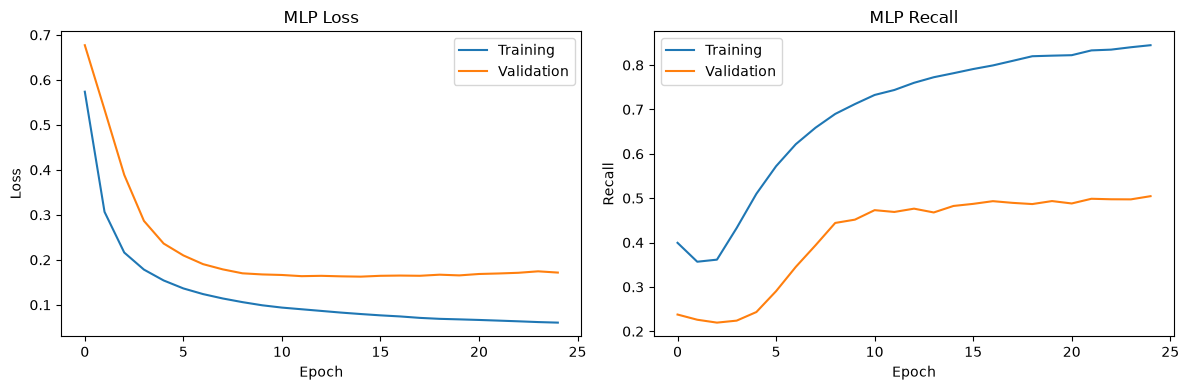

In [238]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Training and validation loss
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("MLP Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

# Training and validation recall
plt.subplot(1, 2, 2)
plt.plot(history.history["recall"], label="Training")
plt.plot(history.history["val_recall"], label="Validation")
plt.title("MLP Recall")
plt.xlabel("Epoch")
plt.ylabel("Recall")
plt.legend()

plt.tight_layout()
plt.show()

In [239]:
# Evaluate Keras metrics
mlp_model.evaluate(X_val_tfidf.toarray(), y_val.to_numpy())

# Calculate F1 scores for comparison with Logistic Regression
y_pred = (mlp_model.predict(X_val_tfidf.toarray()) >= 0.5).astype(int)

print("Micro F1:", f1_score(y_val, y_pred, average="micro", zero_division=0))
print("Macro F1:", f1_score(y_val, y_pred, average="macro", zero_division=0))

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1627 - precision: 0.6516 - recall: 0.4824
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
Micro F1: 0.5543914112016557
Macro F1: 0.14163646557432671


In [242]:
# Experiment with different classification thresholds
y_prob = mlp_model.predict(X_val_tfidf.toarray())

for threshold in [0.68, 0.69, 0.70, 0.71]:
    y_pred = (y_prob >= threshold).astype(int)

    micro = f1_score(y_val, y_pred, average="micro", zero_division=0)
    macro = f1_score(y_val, y_pred, average="macro", zero_division=0)
    precision = precision_score(y_val, y_pred, average="micro", zero_division=0)
    recall = recall_score(y_val, y_pred, average="micro", zero_division=0)

    print(f"Threshold: {threshold:.2f}")
    print(f"Micro F1: {micro:.4f} | Macro F1: {macro:.4f}")
    print(f"Precision: {precision:.4f} | Recall: {recall:.4f}\n")

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Threshold: 0.68
Micro F1: 0.4936 | Macro F1: 0.1051
Precision: 0.7175 | Recall: 0.3762

Threshold: 0.69
Micro F1: 0.4895 | Macro F1: 0.1025
Precision: 0.7226 | Recall: 0.3701

Threshold: 0.70
Micro F1: 0.4847 | Macro F1: 0.1003
Precision: 0.7260 | Recall: 0.3638

Threshold: 0.71
Micro F1: 0.4785 | Macro F1: 0.0975
Precision: 0.7282 | Recall: 0.3564



Threshold = 0.69 beats all 4 metrics on the RF baseline.